# Trend Scanning

Introducing to trend scanning method

# Trend Scanning

Introducing to trend scanning method

In [2]:
from pathlib import Path
import pandas as pd

def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "data/crypto_dataset_pipeline/crypto_dataset.py").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")

ROOT = find_project_root()
DATASETS_DIR = ROOT / "data/crypto_dataset_pipeline/data/datasets"

In [3]:
from pathlib import Path
import pandas as pd

directory = Path("../../data/cryptohftdata/derived/datasets/btcusdt_v2/time_1m-bf7241b5e9")
files = sorted(directory.glob("*.parquet"))

df = pd.concat(
    [pd.read_parquet(file) for file in files],
    ignore_index=True
).sort_values("bar_id").reset_index(drop=True)


In [19]:
import pandas as pd

# Timestamp-uri absolute în nanosecunde
datetime_ns_cols = [
    "decision_time_ns",
    "eval_time_ns",
    "t_start_ns",
    "t_end_ns",
    "t_open_recv_ns",
    "t_close_recv_ns",
    "oi_reference_ts_ns",
]

# Timestamp-uri absolute în milisecunde
datetime_ms_cols = [
    "m_open_ms",
    "m_close_ms",
]

for col in datetime_ns_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], unit="ns", utc=True)

for col in datetime_ms_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], unit="ms", utc=True)

# Verificare
print(df[[c for c in datetime_ns_cols + datetime_ms_cols
          if c in df.columns]].dtypes)

decision_time_ns      datetime64[ns, UTC]
eval_time_ns          datetime64[ns, UTC]
t_start_ns            datetime64[ns, UTC]
t_end_ns              datetime64[ns, UTC]
t_open_recv_ns        datetime64[ns, UTC]
t_close_recv_ns       datetime64[ns, UTC]
oi_reference_ts_ns    datetime64[ns, UTC]
m_open_ms             datetime64[ns, UTC]
m_close_ms            datetime64[ns, UTC]
dtype: object


In [5]:
df = df.set_index("bar_id", verify_integrity=True)
df = df.sort_index()

print(df.index.is_unique)
print(df.index.is_monotonic_increasing)

True
True


In [6]:
df = df[~df.index.duplicated(keep="first")]

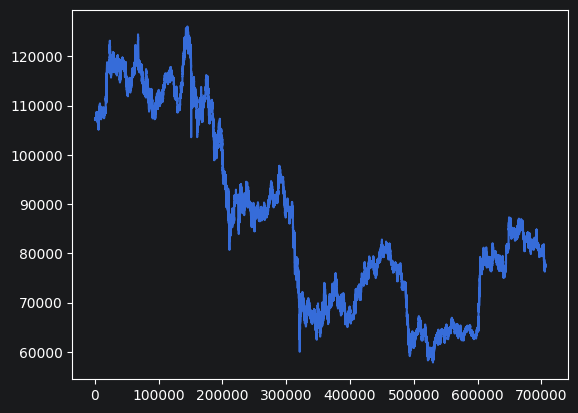

In [12]:
import matplotlib.pyplot as plt

plt.plot(df.bar_close)

## CUSUM Filter

For now, we are applying Trend Scanning to the volume-bar dataset using events selected by the CUSUM filter.

There are two distinct approaches worth investigating:

1. **CUSUM-based Trend Scanning:** Treat each CUSUM event as an individual observation and perform Trend Scanning over consecutive CUSUM events.
2. **Volume-bar Trend Scanning:** Use each CUSUM event as a starting point and perform Trend Scanning over the subsequent volume bars.

The first approach captures longer-term trends, while the second focuses on shorter-term, local trends, assuming the same look-forward window.

I will start by testing the first approach and then compare the results to understand how the choice of sampling affects trend identification and labeling.

In [13]:
from mlfinpy.filters import cusum_filter

cusum_events = cusum_filter(
    raw_time_series=df['bar_close'],
    threshold=0.05
)

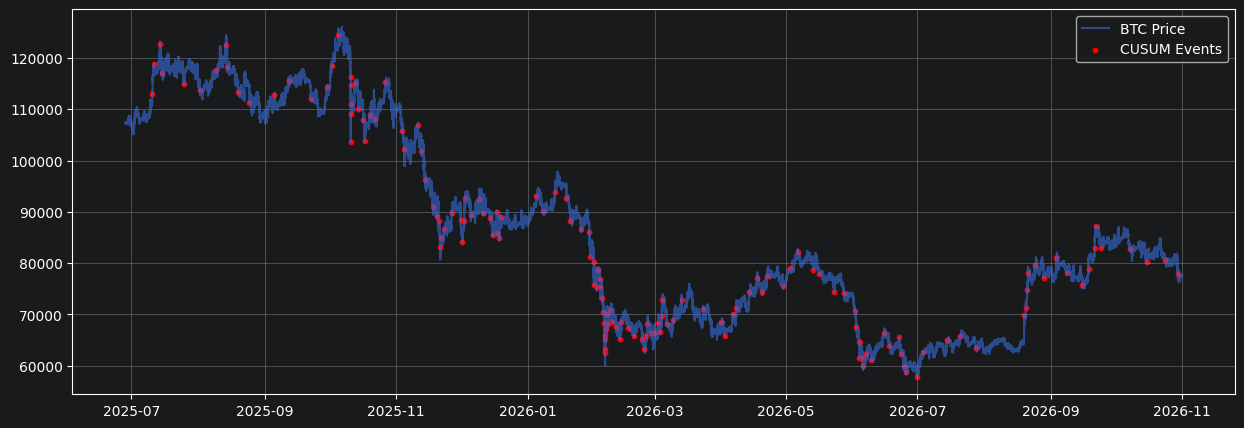

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# Recuperează indicii numerici din DatetimeIndex
event_positions = cusum_events.asi8

# Selectează evenimentele CUSUM după poziție
events = df.iloc[event_positions]

plt.figure(figsize=(15, 5))

plt.plot(df["decision_time_ns"], df["bar_close"],
         alpha=0.6, label="BTC Price")

plt.scatter(events["decision_time_ns"], events["bar_close"],
            s=10, color="red", label="CUSUM Events")

plt.legend()
plt.grid(True)
plt.show()

In [25]:

import pandas as pd
from mlfinpy.filters import cusum_filter
from mlfinpy.labeling import trend_scanning_labels

# 1. Construim seria de prețuri cu index temporal real
data = df.copy()

if "decision_time_ns" in data.columns:
    if pd.api.types.is_numeric_dtype(data["decision_time_ns"]):
        data["decision_time_ns"] = pd.to_datetime(
            data["decision_time_ns"], unit="ns", utc=True
        )
    else:
        data["decision_time_ns"] = pd.to_datetime(
            data["decision_time_ns"], utc=True
        )

    data = data.set_index("decision_time_ns")

data = data.sort_index()
assert isinstance(data.index, pd.DatetimeIndex)
assert data.index.is_unique, "Există timestamp-uri duplicate!"

prices = data["bar_close"].astype(float).dropna()

# 2. Recalculăm evenimentele CUSUM
CUSUM_THRESHOLD = 0.005  # Exemplu: înlocuiește cu pragul anterior

cusum_events = cusum_filter(
    raw_time_series=prices,
    threshold=CUSUM_THRESHOLD
)

# 3. Trend scanning pe seria COMPLETĂ de prețuri
tr_scan_labels = trend_scanning_labels(
    price_series=prices,
    t_events=cusum_events,
    look_forward_window=20,
    min_sample_length=10
)

print(f"Evenimente CUSUM: {len(cusum_events)}")
print(f"Etichete valide: {tr_scan_labels['bin'].notna().sum()}")

display(tr_scan_labels.head())


Evenimente CUSUM: 11840
Etichete valide: 11840


,t1,t_value,ret,bin
2025-06-29 08:33:00+00:00,2025-06-29 08:51:00+00:00,3.268076,0.000788,1.0
2025-06-29 10:11:00+00:00,2025-06-29 10:27:00+00:00,5.125690,0.000727,1.0
2025-06-29 11:56:00+00:00,2025-06-29 12:14:00+00:00,-9.708804,-0.002273,-1.0
2025-06-29 14:39:00+00:00,2025-06-29 14:57:00+00:00,1.846954,0.001388,1.0
2025-06-29 16:31:00+00:00,2025-06-29 16:49:00+00:00,-4.791105,-0.000441,-1.0


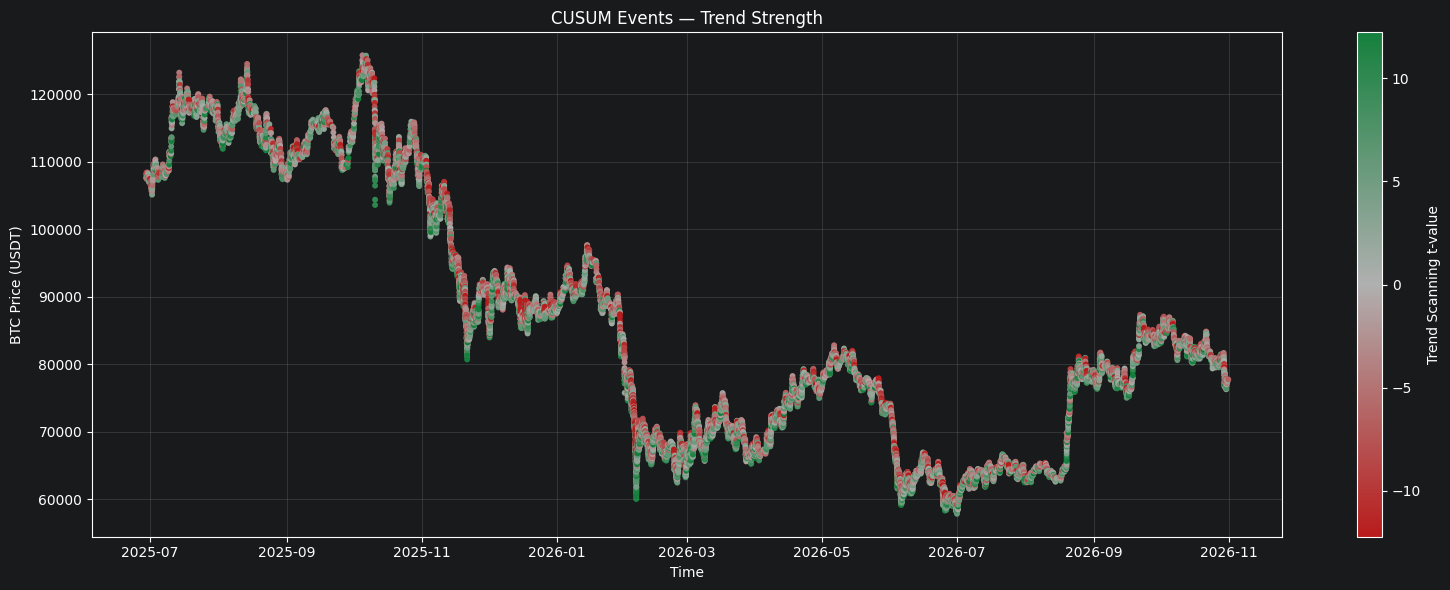

count    11840.000000
mean         0.019590
std          6.634491
min        -30.699665
5%         -10.173043
25%         -4.804372
50%          0.889262
75%          4.900272
95%         10.143347
max         28.759451
Name: t_value, dtype: float64


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

labels = tr_scan_labels.dropna(subset=["t_value"])

# Construim seria de prețuri cu index temporal
prices = (
    df.set_index("decision_time_ns")["bar_close"]
    .astype(float)
    .sort_index()
    .loc[labels.index]
)

t_values = labels["t_value"]

limit = np.percentile(np.abs(t_values), 95)

cmap = LinearSegmentedColormap.from_list(
    "trend", ["#b91c1c", "#b0b0b0", "#15803d"]
)

norm = TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)

plt.figure(figsize=(16, 6))

scatter = plt.scatter(
    prices.index,
    prices,
    c=t_values,
    cmap=cmap,
    norm=norm,
    s=18,
    alpha=1,
    edgecolors="none"
)

plt.colorbar(scatter, label="Trend Scanning t-value")
plt.title("CUSUM Events — Trend Strength")
plt.xlabel("Time")
plt.ylabel("BTC Price (USDT)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(t_values.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]))

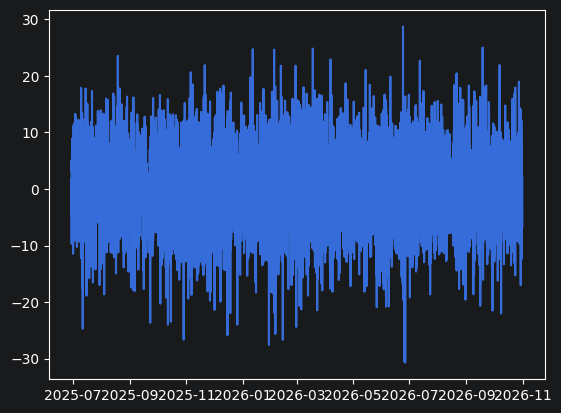

In [30]:
plt.plot(tr_scan_labels["t_value"])
plt.show()

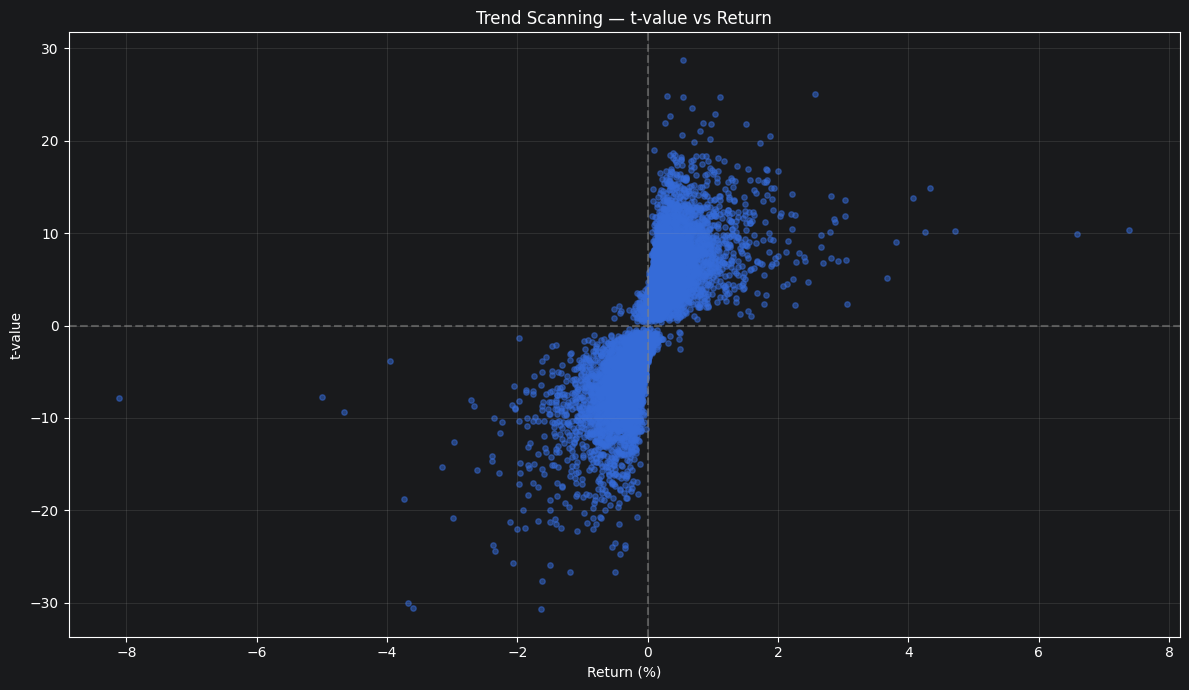

Pearson correlation: 0.7597
Spearman correlation: 0.8993
|t| vs |Return| correlation: 0.4877


In [38]:
import matplotlib.pyplot as plt
import numpy as np

labels = tr_scan_labels.dropna(subset=["t_value", "ret"])

x = labels["ret"] * 100
y = labels["t_value"]

plt.figure(figsize=(12, 7))

plt.scatter(x, y, alpha=0.5, s=15)

plt.axhline(0, color="gray", linestyle="--", alpha=0.6)
plt.axvline(0, color="gray", linestyle="--", alpha=0.6)

plt.xlabel("Return (%)")
plt.ylabel("t-value")
plt.title("Trend Scanning — t-value vs Return")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Corelații
print(f"Pearson correlation: {x.corr(y):.4f}")
print(f"Spearman correlation: {x.corr(y, method='spearman'):.4f}")

# Relația dintre intensitatea trendului și amplitudinea randamentului
print(f"|t| vs |Return| correlation: {x.abs().corr(y.abs()):.4f}")

In [39]:
tr_scan_labels

,t1,t_value,ret,bin
2025-06-29 08:33:00+00:00,2025-06-29 08:51:00+00:00,3.268076,0.000788,1.0
2025-06-29 10:11:00+00:00,2025-06-29 10:27:00+00:00,5.125690,0.000727,1.0
2025-06-29 11:56:00+00:00,2025-06-29 12:14:00+00:00,-9.708804,-0.002273,-1.0
2025-06-29 14:39:00+00:00,2025-06-29 14:57:00+00:00,1.846954,0.001388,1.0
2025-06-29 16:31:00+00:00,2025-06-29 16:49:00+00:00,-4.791105,-0.000441,-1.0
...,...,...,...,...
2026-10-31 00:18:00+00:00,2026-10-31 00:34:00+00:00,-12.374796,-0.002124,-1.0
2026-10-31 01:06:00+00:00,2026-10-31 01:15:00+00:00,-2.423854,-0.001578,-1.0
2026-10-31 03:39:00+00:00,2026-10-31 03:57:00+00:00,-4.132250,-0.000527,-1.0
2026-10-31 10:20:00+00:00,2026-10-31 10:30:00+00:00,2.104986,0.000013,1.0


In [40]:
df_labeled = (
    df.set_index("decision_time_ns")
      .join(tr_scan_labels, how="inner", rsuffix="_trend")
)

df_labeled.head()

,eval_time_ns,t_start_ns,t_end_ns,t_open_recv_ns,t_close_recv_ns,m_open_ms,m_close_ms,first_seq,last_seq,first_trade_id,...,liq_long_to_bid_depth_10bps_1h,activity_vs_ticker24h_2m,activity_vs_ticker24h_15m,activity_vs_ticker24h_1h,rv_ratio_2m_1h_grid1s,liq_any_2m_x_rv_ratio,t1,t_value,ret,bin
2025-06-29 08:33:00+00:00,2025-06-29 08:32:59.999999999+00:00,2025-06-29 08:32:00+00:00,2025-06-29 08:33:00+00:00,2025-06-29 08:32:00.085961778+00:00,2025-06-29 08:32:59.986792916+00:00,2025-06-29 08:31:59.964000+00:00,2025-06-29 08:32:59.864000+00:00,757241,760101,6437169041,...,0.000018,22.647477,3.633527,1.988245,19.741049,19.741049,2025-06-29 08:51:00+00:00,3.268076,0.000788,1.0
2025-06-29 10:11:00+00:00,2025-06-29 10:10:59.999999999+00:00,2025-06-29 10:10:00+00:00,2025-06-29 10:11:00+00:00,2025-06-29 10:10:00.099040774+00:00,2025-06-29 10:10:59.919714166+00:00,2025-06-29 10:09:59.972000+00:00,2025-06-29 10:10:59.793000+00:00,930118,931913,6437341962,...,0.000000,3.926001,7.218705,4.267708,0.956991,0.000000,2025-06-29 10:27:00+00:00,5.125690,0.000727,1.0
2025-06-29 11:56:00+00:00,2025-06-29 11:55:59.999999999+00:00,2025-06-29 11:55:00+00:00,2025-06-29 11:56:00+00:00,2025-06-29 11:55:00.057719853+00:00,2025-06-29 11:55:59.892458587+00:00,2025-06-29 11:54:59.932000+00:00,2025-06-29 11:55:59.767000+00:00,1132268,1136625,6437544157,...,0.000000,22.138634,4.154826,1.890084,16.095650,16.095650,2025-06-29 12:14:00+00:00,-9.708804,-0.002273,-1.0
2025-06-29 14:39:00+00:00,2025-06-29 14:38:59.999999999+00:00,2025-06-29 14:38:00+00:00,2025-06-29 14:39:00+00:00,2025-06-29 14:38:00.024985427+00:00,2025-06-29 14:38:59.934015855+00:00,2025-06-29 14:37:59.901000+00:00,2025-06-29 14:38:59.809000+00:00,1316154,1325291,6437728087,...,0.005672,9.674984,2.514607,1.290684,13.172103,13.172103,2025-06-29 14:57:00+00:00,1.846954,0.001388,1.0
2025-06-29 16:31:00+00:00,2025-06-29 16:30:59.999999999+00:00,2025-06-29 16:30:00+00:00,2025-06-29 16:31:00+00:00,2025-06-29 16:30:00.019633505+00:00,2025-06-29 16:30:59.839160019+00:00,2025-06-29 16:29:59.897000+00:00,2025-06-29 16:30:59.718000+00:00,1474776,1477267,6437886728,...,0.016681,3.544325,2.957743,2.284001,2.087252,0.000000,2025-06-29 16:49:00+00:00,-4.791105,-0.000441,-1.0


In [41]:
df_labeled = df_labeled.loc[:, df_labeled.isna().mean() <= 0.10]

In [42]:
df_labeled.dropna(inplace=True)

In [43]:
df_labeled.shape

(8499, 493)

In [44]:
list(df_labeled)

['eval_time_ns',
 't_start_ns',
 't_end_ns',
 't_open_recv_ns',
 't_close_recv_ns',
 'm_open_ms',
 'm_close_ms',
 'first_seq',
 'last_seq',
 'first_trade_id',
 'last_trade_id',
 'seg',
 'close_reason',
 'complete',
 'threshold_int',
 'feed_complete',
 'bar_open',
 'bar_high',
 'bar_low',
 'bar_close',
 'bar_n_trades',
 'bar_volume_btc',
 'bar_notional_usdt',
 'bar_vwap',
 'bar_return_log',
 'bar_oc_log',
 'bar_range_log',
 'bar_close_location',
 'bar_tfi_btc',
 'bar_tfi_usdt',
 'bar_tfi_ratio',
 'bar_count_imbalance',
 'bar_mean_trade_size_btc',
 'bar_duration_s',
 'bar_volume_rate_btc_s',
 'bar_notional_rate_usdt_s',
 'last_trade_price',
 'last_trade_age_ms',
 'tw_state_5s',
 'tw_state_30s',
 'tw_state_2m',
 'tw_state_15m',
 'tw_state_1h',
 'tw_state_4h',
 'tw_state_24h',
 'trade_count_5s',
 'volume_5s_btc',
 'notional_5s_usdt',
 'trade_rate_5s_per_s',
 'volume_rate_5s_btc_s',
 'notional_rate_5s_usdt_s',
 'tfi_5s_btc',
 'tfi_5s_usdt',
 'tfi_ratio_5s',
 'count_imbalance_5s',
 'mean_tra

In [59]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    confusion_matrix,
    balanced_accuracy_score
)
from pandas.api.types import is_numeric_dtype
# Coloane care NU trebuie utilizate drept features
exclude_cols = {
    # Etichete și informații viitoare
    "t1",
    "t_value",
    "ret",
    "bin",

    # Timestamp-uri absolute
    "decision_time_ns",
    "eval_time_ns",
    "t_start_ns",
    "t_end_ns",
    "t_open_recv_ns",
    "t_close_recv_ns",
    "m_open_ms",
    "m_close_ms",
    "oi_reference_ts_ns",

    # Identificatori
    "first_seq",
    "last_seq",
    "first_trade_id",
    "last_trade_id",

    # Metadate de construcție a barelor
    "seg",
    "close_reason",
    "threshold_int",
    "complete",
    "feed_complete",
}

# Stările disponibile la momentul deciziei pot fi categorice
state_cols = [
    c for c in df_labeled.columns
    if c.endswith("_state") or c.startswith("tw_state_")
]

# Toate feature-urile numerice + stările categorice
features = [
    c for c in df_labeled.columns
    if c not in exclude_cols
    and (
        is_numeric_dtype(df_labeled[c])
        or c in state_cols
    )
]


# 2. Prepare dataset
data = df_labeled.sort_index().copy()

# Binary classification: -1 = Downtrend, +1 = Uptrend
data = data[data["bin"].isin([-1, 1])]

# 3. Chronological train/test split (80/20)
split_idx = int(len(data) * 0.8)

train = data.iloc[:split_idx].copy()
test = data.iloc[split_idx:].copy()

# 4. Purging: remove training labels overlapping test period
test_start = pd.to_datetime(test.index[0], utc=True)
train_t1 = pd.to_datetime(train["t1"], utc=True)

train = train.loc[train_t1 < test_start]

# 5. Features and target
X_train = train[features]
y_train = train["bin"].astype(int)

X_test = test[features]
y_test = test["bin"].astype(int)

print(f"Train samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")
print(f"Features: {len(features)}")

# 6. Random Forest
model = RandomForestClassifier(
    n_estimators=500,
    max_depth=6,
    min_samples_leaf=8,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# 7. Predictions
y_pred = model.predict(X_test)

positive_idx = list(model.classes_).index(1)
y_proba = model.predict_proba(X_test)[:, positive_idx]

# 8. Evaluation
print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(
    y_test,
    y_pred,
    labels=[-1, 1],
    target_names=["Downtrend", "Uptrend"],
    zero_division=0
))

print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")

if y_test.nunique() == 2:
    print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")
else:
    print("ROC-AUC unavailable: test set contains one class.")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[-1, 1]))

Train samples: 6798
Test samples: 1700
Features: 472

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

   Downtrend       0.52      0.51      0.52       845
     Uptrend       0.52      0.53      0.52       855

    accuracy                           0.52      1700
   macro avg       0.52      0.52      0.52      1700
weighted avg       0.52      0.52      0.52      1700

Balanced Accuracy: 0.5200
ROC-AUC: 0.5235

Confusion Matrix:
[[434 411]
 [405 450]]


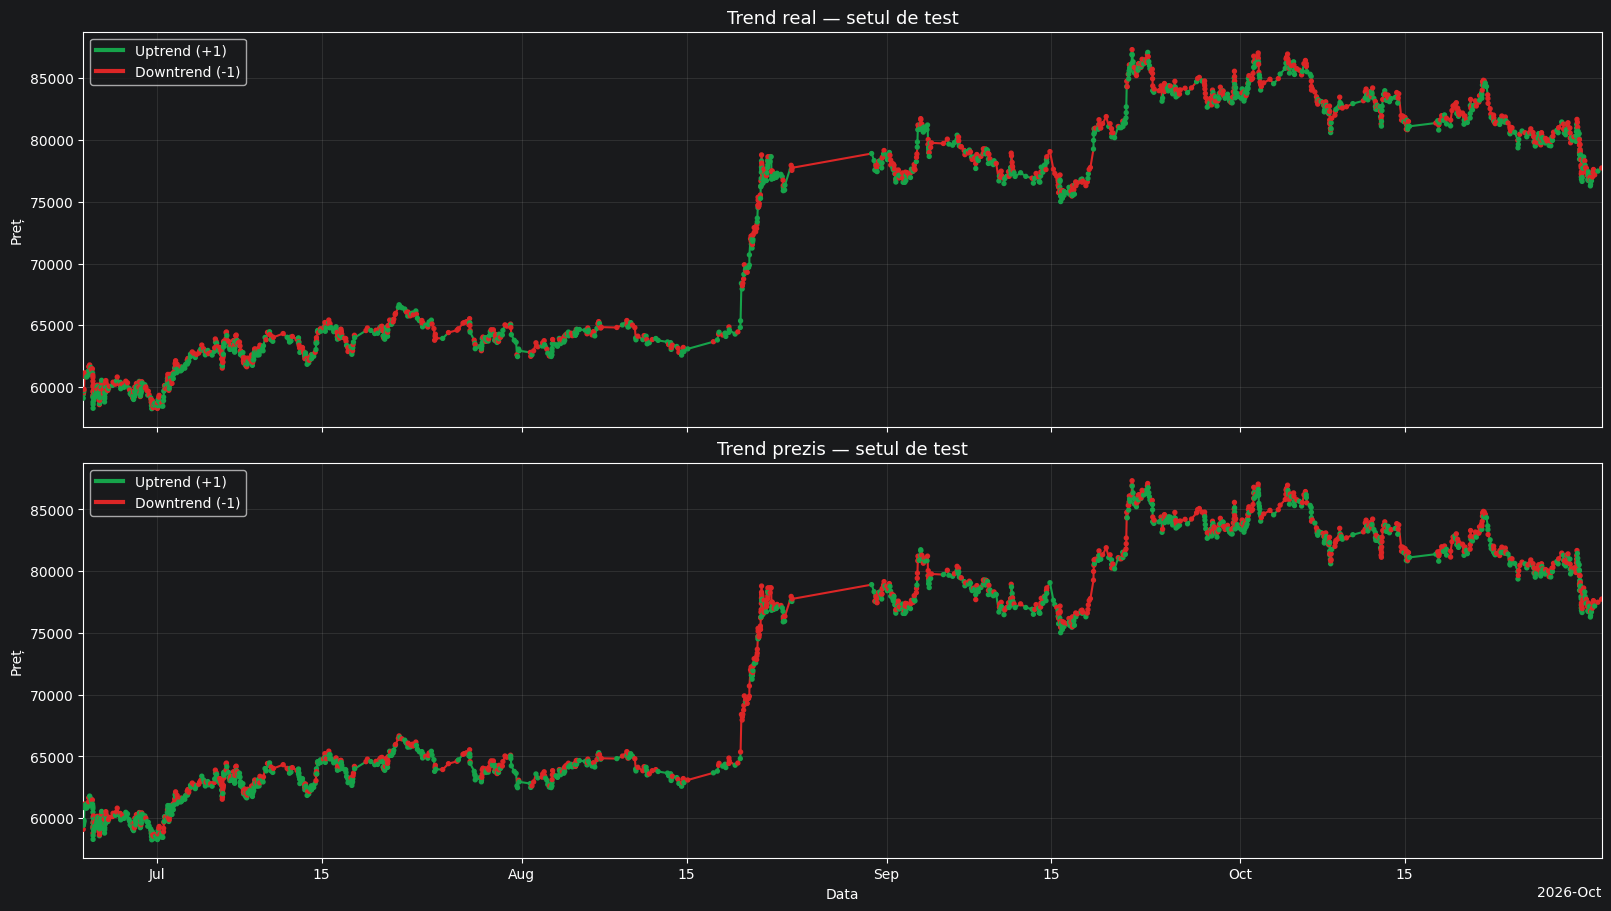

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

# 1. Prețurile și etichetele, în aceeași ordine ca predicțiile
test_prices = (
    test["bar_close"]
    if "bar_close" in test.columns
    else df["bar_close"].reindex(test.index)
)

prices = pd.to_numeric(test_prices, errors="coerce").to_numpy()
actual = test["bin"].astype(int).to_numpy()
predicted = np.asarray(y_pred).reshape(-1)

if not (len(prices) == len(actual) == len(predicted)):
    raise ValueError("Prețurile, etichetele și predicțiile nu sunt aliniate.")

if len(prices) < 2 or not np.isfinite(prices).all():
    raise ValueError("Sunt necesare cel puțin două prețuri valide.")

if not np.isin(predicted, [-1, 1]).all():
    raise ValueError("Predicțiile trebuie să fie -1 sau +1.")

dates = mdates.date2num(pd.DatetimeIndex(test.index).to_pydatetime())

UP_COLOR = "#16a34a"
DOWN_COLOR = "#dc2626"

# 2. Funcție pentru desenarea prețului colorat
def plot_trends(ax, labels, title):
    colors = np.where(labels == 1, UP_COLOR, DOWN_COLOR)

    points = np.column_stack([dates, prices])
    segments = np.stack([points[:-1], points[1:]], axis=1)

    # Segmentul primește culoarea etichetei barei de la început.
    collection = LineCollection(
        segments,
        colors=colors[:-1],
        linewidths=1.5,
    )
    ax.add_collection(collection)

    # Fiecare punct are culoarea propriei etichete.
    ax.scatter(dates, prices, c=colors, s=8, zorder=3)

    ax.set_xlim(dates[0], dates[-1])
    ax.autoscale_view(scalex=False, scaley=True)
    ax.xaxis_date()
    ax.set_title(title, fontsize=13)
    ax.set_ylabel("Preț")
    ax.grid(alpha=0.2)

# 3. Aceleași axe pentru comparație
fig, axes = plt.subplots(
    2, 1,
    figsize=(16, 9),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

plot_trends(axes[0], actual, "Trend real — setul de test")
plot_trends(axes[1], predicted, "Trend prezis — setul de test")

legend = [
    Line2D([0], [0], color=UP_COLOR, lw=3, label="Uptrend (+1)"),
    Line2D([0], [0], color=DOWN_COLOR, lw=3, label="Downtrend (-1)"),
]

for ax in axes:
    ax.legend(handles=legend, loc="upper left")

locator = mdates.AutoDateLocator()
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
axes[1].set_xlabel("Data")

plt.show()